In [ ]:
# Installing necessary packages to run future code

%pip install pandas numpy scikit-learn matplotlib
%pip install openpyxl
%pip install scikit-learn

In [7]:
# Organising environmental sensor data so that it is in a nice format

import json
from pathlib import Path

import pandas as pd

DATA_DIR = Path("data")  # put your three files in a "data" folder next to this script

# 1. Load files (default C engine; no rows are silently skipped)
environmental_df = pd.read_csv(DATA_DIR / "Environmental sensor.csv")

# Ensure the columns index and row index are flat and clean
environmental_df.columns = [str(col) for col in environmental_df.columns]
environmental_df.reset_index(drop=True, inplace=True)

# 2. Define the JSON parsing helper function
def parse_sensor_json(json_str):
    if pd.isna(json_str):
        return {}
    try:
        if isinstance(json_str, str):
            if json_str.startswith('""') or '""' in json_str:
                json_str = json_str.replace('""', '"')
            if json_str.startswith('"') and json_str.endswith('"'):
                json_str = json_str[1:-1]
            data = json.loads(json_str)
        else:
            data = json_str
            
        extracted = {}
        if isinstance(data, list):
            for item in data:
                var_info = item.get('variable', {})
                var_name = var_info.get('name')
                values_list = item.get('values', [])
                if values_list and isinstance(values_list, list):
                    metric_value = values_list[0].get('value')
                    if var_name is not None:
                        extracted[var_name] = metric_value
        return extracted
    except Exception:
        return {}

# 3. Parse and extract key-value metrics from environmental data
parsed_metrics = environmental_df['jsondata'].apply(parse_sensor_json)
metrics_df = pd.DataFrame(parsed_metrics.tolist())
metrics_df.reset_index(drop=True, inplace=True)

# Map standard headings to include units explicitly
unit_mapping = {
    'Battery': 'Battery (V)',
    'Carbon dioxide': 'Carbon dioxide (ppm)',
    'Humidity': 'Humidity (%)',
    'Formaldehyde': 'Formaldehyde (mg/m³)',
    'Pressure': 'Pressure (mb)',
    'Temperature': 'Temperature (°C)',
    'Light': 'Light (lx)',
    'Light Volatile Organic Compounds': 'Light Volatile Organic Compounds (ppb)',
    'Particulate matter 1': 'Particulate matter 1 (µg/m³)',
    'Particulate matter 4': 'Particulate matter 4 (µg/m³)',
    'Particulate matter 2.5': 'Particulate matter 2.5 (µg/m³)',
    'Particulate matter 10': 'Particulate matter 10 (µg/m³)'
}
metrics_df.rename(columns=unit_mapping, inplace=True)

# 4. Combine extracted metrics with the original DataFrame (dropping original raw JSON column)
environmental_expanded_df = pd.concat(
    [environmental_df.drop(columns=['jsondata']), metrics_df],
    axis=1
)

# 5. Display summaries and verify columns directly
print("--- Verified Column Names in Environmental Data ---")
for col in environmental_expanded_df.columns:
    print(f" - {col}")

print("\n--- Expanded Environmental Sensor Data with Units ---")
display(environmental_expanded_df.head())



--- Verified Column Names in Environmental Data ---
 - id
 - sensorid
 - devicetype
 - status
 - processing_errors
 - createdate
 - processdate
 - Battery (V)
 - Carbon dioxide (ppm)
 - Humidity (%)
 - Formaldehyde (mg/m³)
 - Pressure (mb)
 - Temperature (°C)
 - Light Volatile Organic Compounds (ppb)
 - Particulate matter 1 (µg/m³)
 - Particulate matter 4 (µg/m³)
 - Particulate matter 2.5 (µg/m³)
 - Particulate matter 10 (µg/m³)

--- Expanded Environmental Sensor Data with Units ---


,id,sensorid,devicetype,status,processing_errors,createdate,processdate,Battery (V),Carbon dioxide (ppm),Humidity (%),Formaldehyde (mg/m³),Pressure (mb),Temperature (°C),Light Volatile Organic Compounds (ppb),Particulate matter 1 (µg/m³),Particulate matter 4 (µg/m³),Particulate matter 2.5 (µg/m³),Particulate matter 10 (µg/m³)
0,2,6012002000241,env,Processed,NaN,2024-02-29 03:11:58.210358+11,2024-02-29 03:11:58.210358+11,4.1875,603,66,6.0,1011,23.8,14.0,8.0,9.0,9.0,9.0
1,4,6012002000241,env,Processed,NaN,2024-02-29 17:09:08.833822+11,2024-02-29 17:09:08.833822+11,4.1875,603,66,6.0,1011,23.8,14.0,8.0,9.0,9.0,9.0
2,5,6012002000326,env,Processed,NaN,2024-02-29 17:09:12.444245+11,2024-02-29 17:09:12.444245+11,4.1875,525,68,5.0,1012,23.8,7.0,6.0,6.0,6.0,6.0
3,16,6012002000777,env,Processed,NaN,2024-02-29 17:10:24.443407+11,2024-02-29 17:10:24.443407+11,4.1562,425,51,1.0,1015,18.8,71.0,1.0,3.0,3.0,4.0
4,24,6012002000869,env,Processed,NaN,2024-02-29 17:11:11.348578+11,2024-02-29 17:11:11.348578+11,4.1250,465,56,17.0,1010,24.3,0.0,2.0,2.0,2.0,2.0


In [ ]:
# Shuffle all rows into a random order and split 75% / 25%
# random_state makes the shuffle reproducible (same split every run)

data_lot_1 = environmental_expanded_df.sample(frac=0.75, random_state=42)           # 75% split
data_lot_2 = environmental_expanded_df.drop(data_lot_1.index).sample(frac=1, random_state=42)  # remaining 25%, also shuffled

# NOTE: random_state=42 keeps the data split the same for multiple reruns of the data

print(f"Total rows:  {len(environmental_expanded_df)}")
print(f"Data lot 1:  {len(data_lot_1)} ({len(data_lot_1)/len(environmental_expanded_df):.1%})")
print(f"Data lot 2:  {len(data_lot_2)} ({len(data_lot_2)/len(environmental_expanded_df):.1%})")
print("Any overlap:", bool(set(data_lot_1.index) & set(data_lot_2.index)))



In [33]:
# Multiple linear regression code using lot 1

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Find a column by its name, ignoring the unit in brackets (avoids unit-label mismatches)
def find_col(df, name):
    matches = [c for c in df.columns if c.startswith(name + " (")]
    if len(matches) != 1:
        raise KeyError(f"Expected one column for '{name}', found {matches}")
    return matches[0]

predictor_names = ["Carbon dioxide", "Temperature", "Humidity", "Pressure"]
target_names = ["Formaldehyde", "Light Volatile Organic Compounds",
                "Particulate matter 1", "Particulate matter 2.5",
                "Particulate matter 4", "Particulate matter 10"]

X_cols = [find_col(data_lot_1, n) for n in predictor_names]
y_cols = [find_col(data_lot_1, n) for n in target_names]

models = {}     # fitted models, kept so they can be applied to data lot 2 later
bounds = {}     # (lower, upper) physical limits per target, taken from the training data
results = []
coefs = {}

for y_col in y_cols:
    # Only rows where this target was actually measured can be used for training
    train = data_lot_1[X_cols + [y_col]].dropna()
    X_train, y_train = train[X_cols], train[y_col]

    model = LinearRegression().fit(X_train, y_train)

    # Physical constraint: concentrations cannot be negative, and estimates
    # should not exceed the largest value actually observed in training
    lower = max(0.0, y_train.min())
    upper = y_train.max()
    bounds[y_col] = (lower, upper)

    pred_raw = model.predict(X_train)
    pred = np.clip(pred_raw, lower, upper)

    models[y_col] = model
    coefs[y_col] = pd.Series(model.coef_, index=X_cols)
    results.append({
        "target": y_col,
        "rows_used": len(train),
        "intercept": model.intercept_,
        "R2_raw": r2_score(y_train, pred_raw),
        "R2_clipped": r2_score(y_train, pred),
        "MAE_raw": mean_absolute_error(y_train, pred_raw),
        "MAE_clipped": mean_absolute_error(y_train, pred),
        "RMSE_clipped": np.sqrt(mean_squared_error(y_train, pred)),
        "mean_baseline_MAE": mean_absolute_error(y_train, np.full(len(y_train), y_train.mean())),
        "pct_rows_clipped": 100 * np.mean((pred_raw < lower) | (pred_raw > upper)),
    })
print("Comparison of bounded vs non-bounded inputs in data lot 1")
print(pd.DataFrame(results).round(3).to_string(index=False))
print()
print("Coefficients for inputs in data lot 1")
print(pd.DataFrame(coefs).round(4))


def predict_rows(df):
    """Estimate every target for every row of df, clipped to physical limits.

    Parameters
    ----------
    df : DataFrame containing the four predictor columns (X_cols).

    Returns
    -------
    DataFrame with the id (if present), the four predictors, and one
    'Estimated <target>' column per target. Rows with a missing predictor
    get NaN estimates.
    """
    out = df[(["id"] if "id" in df.columns else []) + X_cols].copy()
    valid = df[X_cols].notna().all(axis=1)
    for y_col in y_cols:
        lower, upper = bounds[y_col]
        est = pd.Series(np.nan, index=df.index)
        est[valid] = np.clip(models[y_col].predict(df.loc[valid, X_cols]), lower, upper)
        out["Estimated " + y_col] = est
    return out


# Estimates for every row in data lot 1
estimates_lot_1 = predict_rows(data_lot_1)
print()
print("Estimates for every row in data lot 1")
print(estimates_lot_1.head().round(2).to_string())

Comparison of bounded vs non-bounded inputs in data lot 1
                                target  rows_used  intercept  R2_raw  R2_clipped  MAE_raw  MAE_clipped  RMSE_clipped  mean_baseline_MAE  pct_rows_clipped
                  Formaldehyde (mg/m³)      49609   -205.831   0.765       0.776    4.411        4.358         7.326             12.030             0.863
Light Volatile Organic Compounds (ppb)     112392   -460.690   0.007       0.008   15.437       15.399        67.429             14.270             0.664
          Particulate matter 1 (µg/m³)     133310   -209.075   0.328       0.331    1.703        1.685         2.682              2.502             2.319
        Particulate matter 2.5 (µg/m³)     133310   -203.937   0.256       0.256    2.024        2.014         3.131              2.781             1.520
          Particulate matter 4 (µg/m³)     133310   -211.914   0.235       0.236    2.139        2.125         3.323              2.905             1.732
         Particula

In [35]:
# Test multiple linear regression using lot 2

import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# ---- Score the estimates against the measured values in lot 2 ----
# Only rows where the target was actually measured (and all predictors are present) can be scored
results_lot_2 = []
for y_col in y_cols:
    known = data_lot_2[y_col].notna() & data_lot_2[X_cols].notna().all(axis=1)
    y_true = data_lot_2.loc[known, y_col].to_numpy(float)

    # Raw prediction (no clipping) and clipped prediction
    pred_raw = models[y_col].predict(data_lot_2.loc[known, X_cols])
    lower, upper = bounds[y_col]
    pred = np.clip(pred_raw, lower, upper)

    # Baseline: always predict the lot 1 mean of this target (same baseline as the interpolation test)
    baseline_pred = np.full(len(y_true), data_lot_1[y_col].mean())
    mean_baseline_mae = mean_absolute_error(y_true, baseline_pred)
    mae_clipped = mean_absolute_error(y_true, pred)

    results_lot_2.append({
        "target": y_col,
        "rows_scored": int(known.sum()),
        "R2_raw": r2_score(y_true, pred_raw),
        "R2_clipped": r2_score(y_true, pred),
        "MAE_raw": mean_absolute_error(y_true, pred_raw),
        "MAE_clipped": mae_clipped,
        "RMSE_clipped": np.sqrt(mean_squared_error(y_true, pred)),
        "mean_baseline_MAE": mean_baseline_mae,
        "skill_vs_baseline": 1 - mae_clipped / mean_baseline_mae,
        "MAE_pct_of_mean": 100 * mae_clipped / y_true.mean(),
        "pct_rows_clipped": 100 * np.mean((pred_raw < lower) | (pred_raw > upper)),
    })

regression_eval_lot_2 = pd.DataFrame(results_lot_2)
print("Scores estimates in data lot 2")
print(regression_eval_lot_2.round(3).to_string(index=False))

# ---- Coefficients (the same models as lot 1, shown for reference) ----
print()
print("Coefficients for inputs in data lot 2")
print(pd.DataFrame(coefs).round(4))

# ---- Estimates for every row of lot 2 ----
# Uses only the models and clipping bounds fitted on data lot 1
estimates_lot_2 = predict_rows(data_lot_2)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
print()
print("Estimates for every row in data lot 2")
print(estimates_lot_2.head().round(2).to_string(index=False))

Scores estimates in data lot 2
                                target  rows_scored  R2_raw  R2_clipped  MAE_raw  MAE_clipped  RMSE_clipped  mean_baseline_MAE  skill_vs_baseline  MAE_pct_of_mean  pct_rows_clipped
                  Formaldehyde (mg/m³)        16458   0.757       0.768    4.472        4.420         7.420             12.008              0.632           36.218             0.930
Light Volatile Organic Compounds (ppb)        37489   0.007       0.007   16.152       16.115        82.231             14.963             -0.077          103.425             0.686
          Particulate matter 1 (µg/m³)        44428   0.308       0.311    1.722        1.703         2.808              2.519              0.324           45.915             2.413
        Particulate matter 2.5 (µg/m³)        44428   0.242       0.243    2.041        2.030         3.253              2.796              0.274           47.541             1.564
          Particulate matter 4 (µg/m³)        44428   0.224     


Predicted values using data lot 1
     id  Carbon dioxide (ppm)  Temperature (°C)  Humidity (%)  Pressure (mb)  Formaldehyde (mg/m³) | from Carbon dioxide (ppm)  Formaldehyde (mg/m³) | from Temperature (°C)  Formaldehyde (mg/m³) | from Humidity (%)  Formaldehyde (mg/m³) | from Pressure (mb)  Light Volatile Organic Compounds (ppb) | from Carbon dioxide (ppm)  Light Volatile Organic Compounds (ppb) | from Temperature (°C)  Light Volatile Organic Compounds (ppb) | from Humidity (%)  Light Volatile Organic Compounds (ppb) | from Pressure (mb)  Particulate matter 1 (µg/m³) | from Carbon dioxide (ppm)  Particulate matter 1 (µg/m³) | from Temperature (°C)  Particulate matter 1 (µg/m³) | from Humidity (%)  Particulate matter 1 (µg/m³) | from Pressure (mb)  Particulate matter 2.5 (µg/m³) | from Carbon dioxide (ppm)  Particulate matter 2.5 (µg/m³) | from Temperature (°C)  Particulate matter 2.5 (µg/m³) | from Humidity (%)  Particulate matter 2.5 (µg/m³) | from Pressure (mb)  Particulate matter 

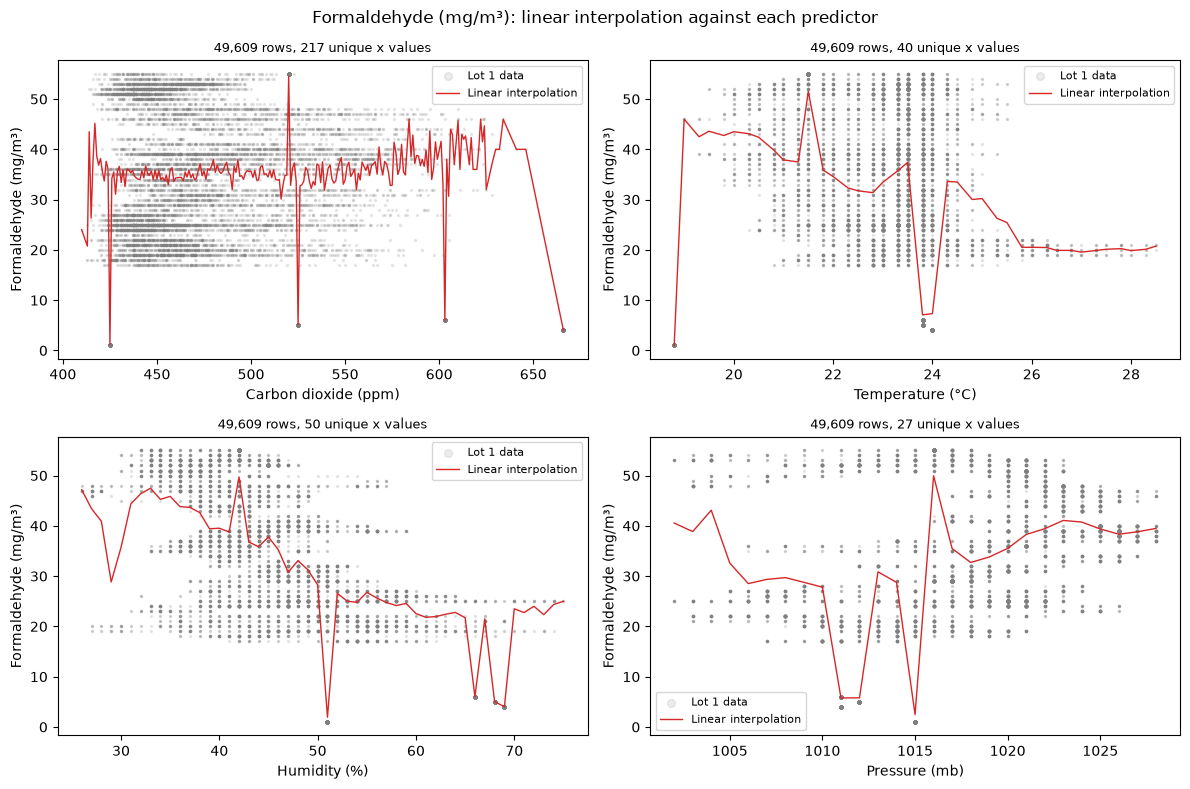

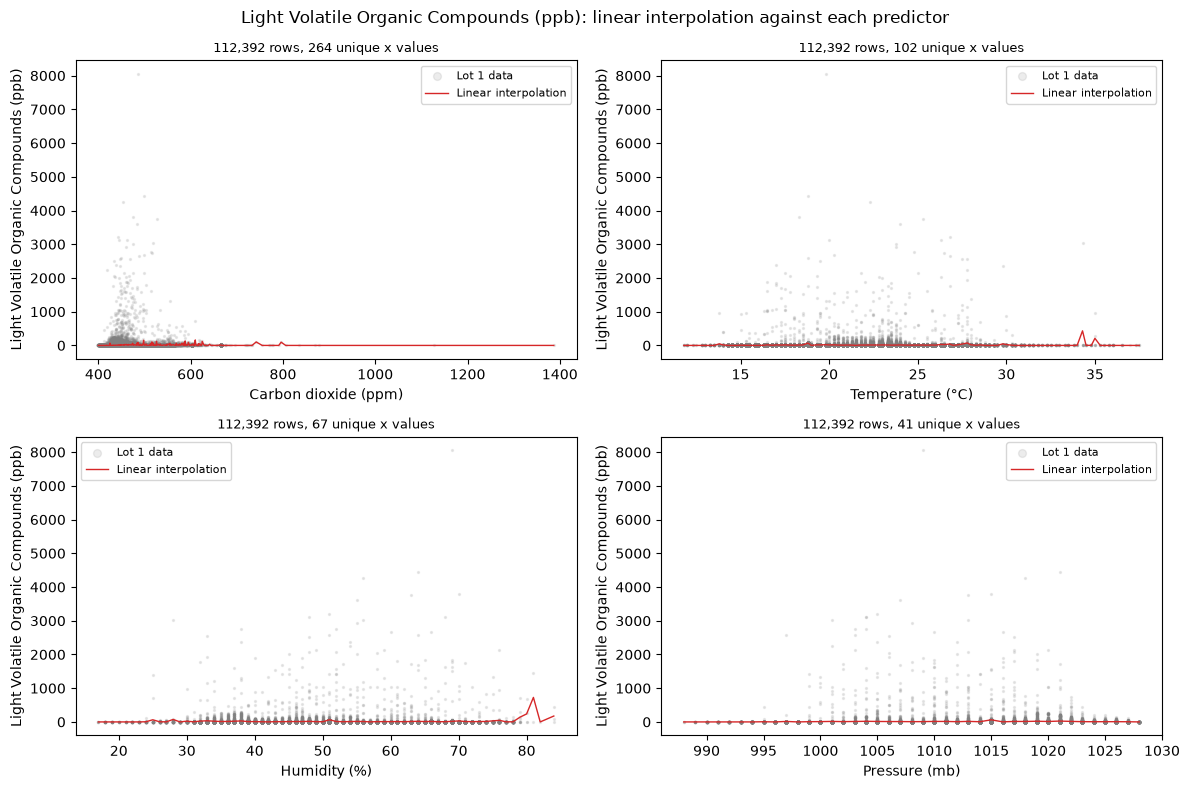

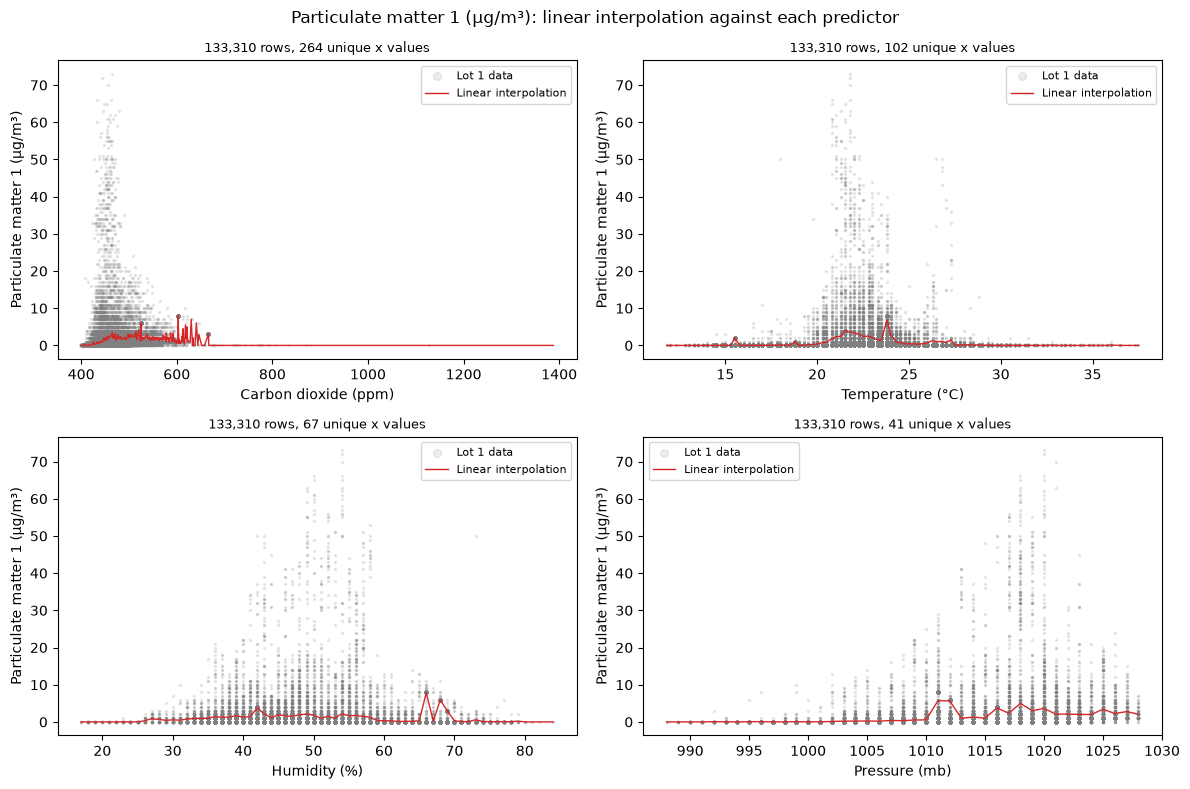

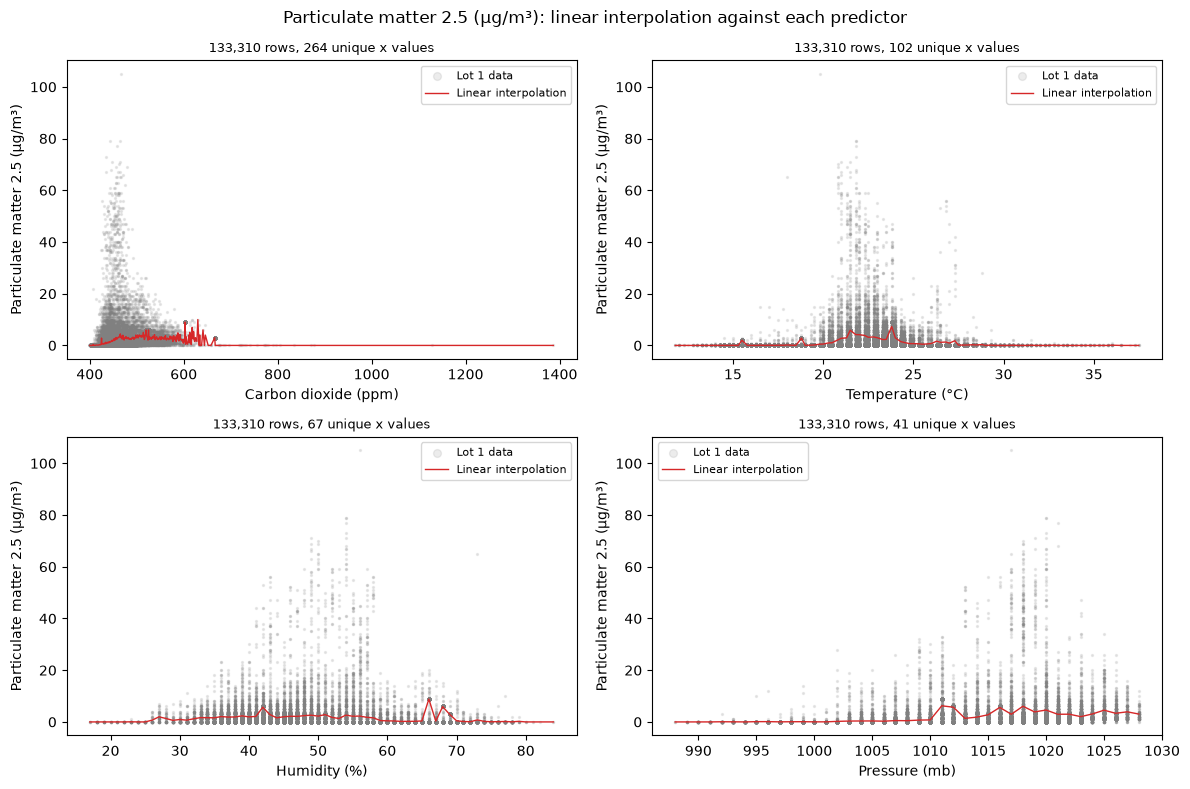

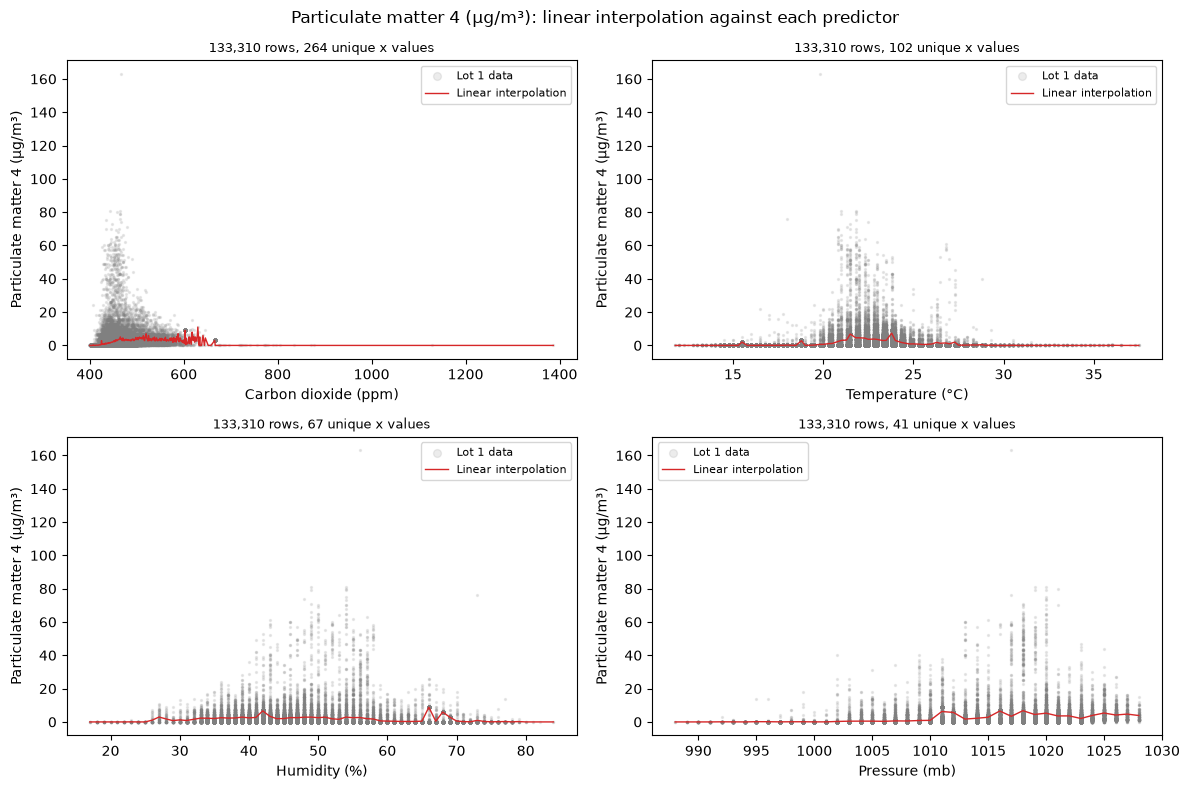

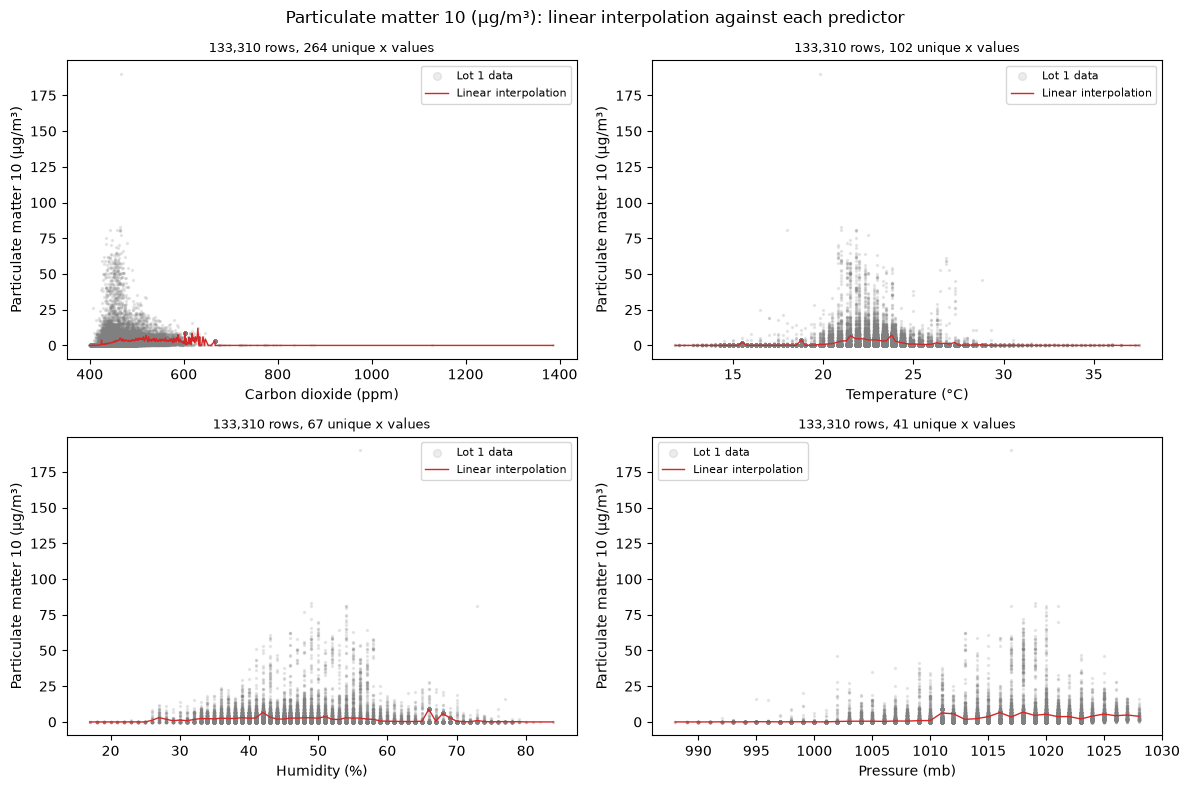

In [ ]:
# Linear interpolation code using lot 1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Build one interpolation table per (target, predictor) pair ----
# np.interp needs x values that are sorted and unique. Many rows share the same
# predictor value (e.g. CO2 = 603), so the target is averaged at each unique x.
interp_tables = {}   # (target, predictor) -> (sorted x, mean y, rows used)

for y_col in y_cols:
    for x_col in X_cols:
        pair = data_lot_1[[x_col, y_col]].dropna()      # rows where both are known
        table = pair.groupby(x_col)[y_col].mean().sort_index()
        interp_tables[(y_col, x_col)] = (table.index.to_numpy(float),
                                         table.to_numpy(float),
                                         len(pair))

def interp_estimate(x_new, y_col, x_col):
    """Linearly interpolate target y_col from predictor x_col.

    Values of x_new outside the training range are held at the nearest end value
    (np.interp default), so estimates never leave the observed range.
    """
    xs, ys, _ = interp_tables[(y_col, x_col)]
    return np.interp(x_new, xs, ys)

# ---- Estimates for every row of a dataframe (24 columns) ----
def interp_rows(df):
    """Return id (if present), the predictors, and one interpolated estimate
    per (target, predictor) pair for every row of df."""
    out = df[(["id"] if "id" in df.columns else []) + X_cols].copy()
    for y_col in y_cols:
        for x_col in X_cols:
            out[f"{y_col} | from {x_col}"] = interp_estimate(df[x_col].to_numpy(float), y_col, x_col)
    return out

# ---- Table first ----
interp_lot_1 = interp_rows(data_lot_1)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
print("Predicted values using data lot 1")
print(interp_lot_1.head().round(2).to_string(index=False))

# ---- Plots: one figure per target, four panels (one per predictor) ----
for y_col in y_cols:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, x_col in zip(axes.ravel(), X_cols):
        xs, ys, n = interp_tables[(y_col, x_col)]
        pair = data_lot_1[[x_col, y_col]].dropna()
        ax.scatter(pair[x_col], pair[y_col], s=2, alpha=0.15, color="grey", label="Lot 1 data")
        ax.plot(xs, ys, color="tab:red", lw=1, label="Linear interpolation")
        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)
        ax.set_title(f"{n:,} rows, {len(xs):,} unique x values", fontsize=9)
        ax.legend(markerscale=4, fontsize=8)
    fig.suptitle(f"{y_col}: linear interpolation against each predictor")
    fig.tight_layout()
    plt.show()

Predicted values using data set 2
     id  Carbon dioxide (ppm)  Temperature (°C)  Humidity (%)  Pressure (mb)  Formaldehyde (mg/m³) | from Carbon dioxide (ppm)  Formaldehyde (mg/m³) | from Temperature (°C)  Formaldehyde (mg/m³) | from Humidity (%)  Formaldehyde (mg/m³) | from Pressure (mb)  Light Volatile Organic Compounds (ppb) | from Carbon dioxide (ppm)  Light Volatile Organic Compounds (ppb) | from Temperature (°C)  Light Volatile Organic Compounds (ppb) | from Humidity (%)  Light Volatile Organic Compounds (ppb) | from Pressure (mb)  Particulate matter 1 (µg/m³) | from Carbon dioxide (ppm)  Particulate matter 1 (µg/m³) | from Temperature (°C)  Particulate matter 1 (µg/m³) | from Humidity (%)  Particulate matter 1 (µg/m³) | from Pressure (mb)  Particulate matter 2.5 (µg/m³) | from Carbon dioxide (ppm)  Particulate matter 2.5 (µg/m³) | from Temperature (°C)  Particulate matter 2.5 (µg/m³) | from Humidity (%)  Particulate matter 2.5 (µg/m³) | from Pressure (mb)  Particulate matter 4

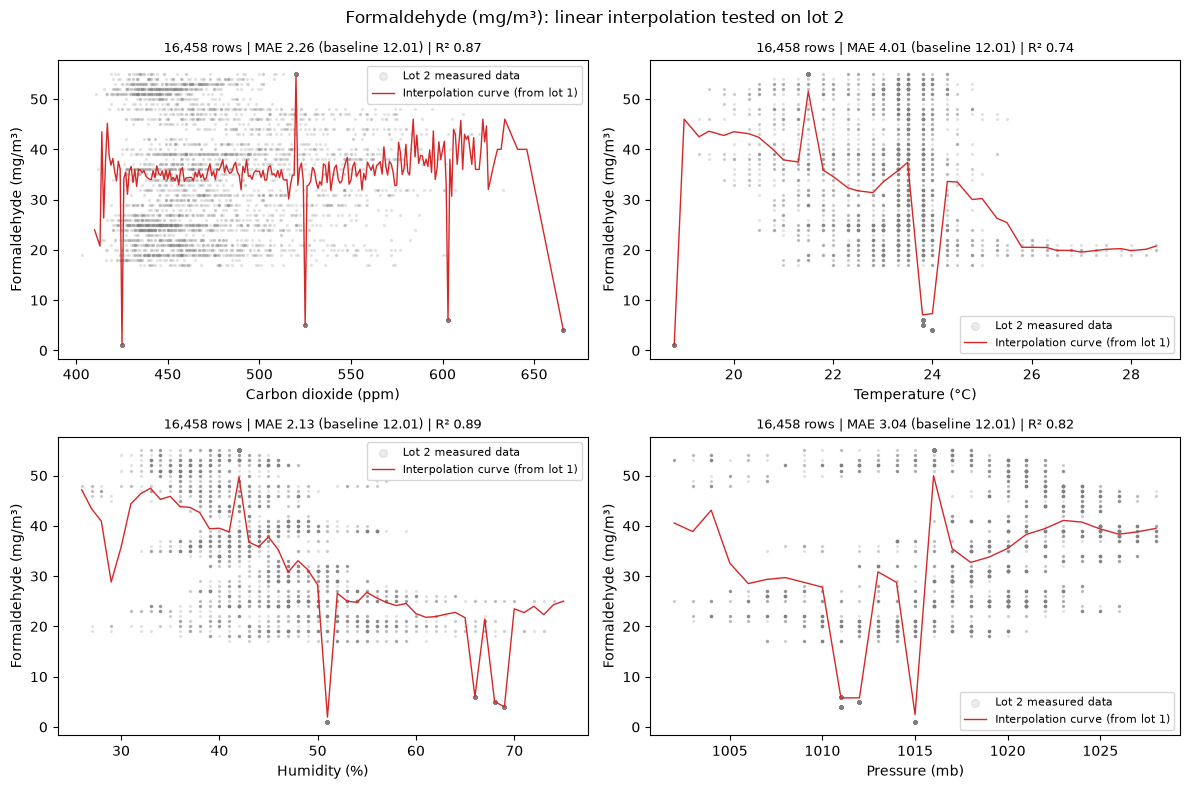

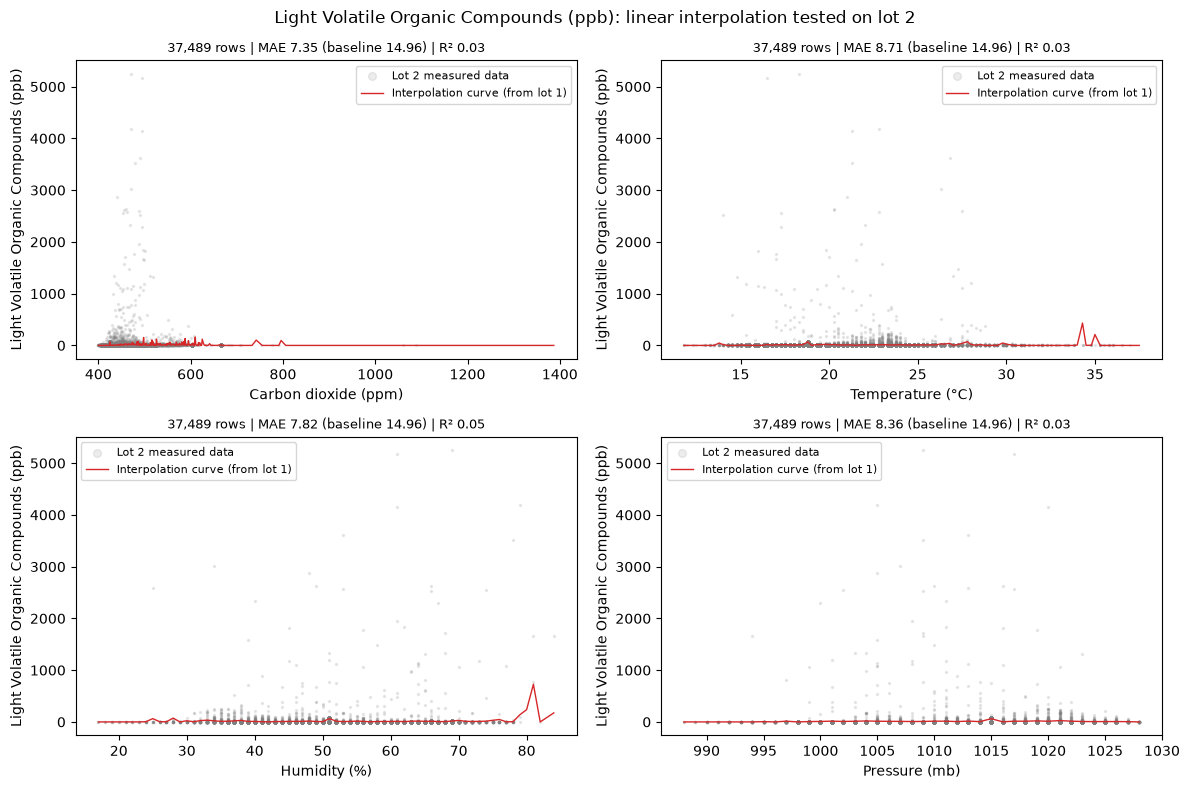

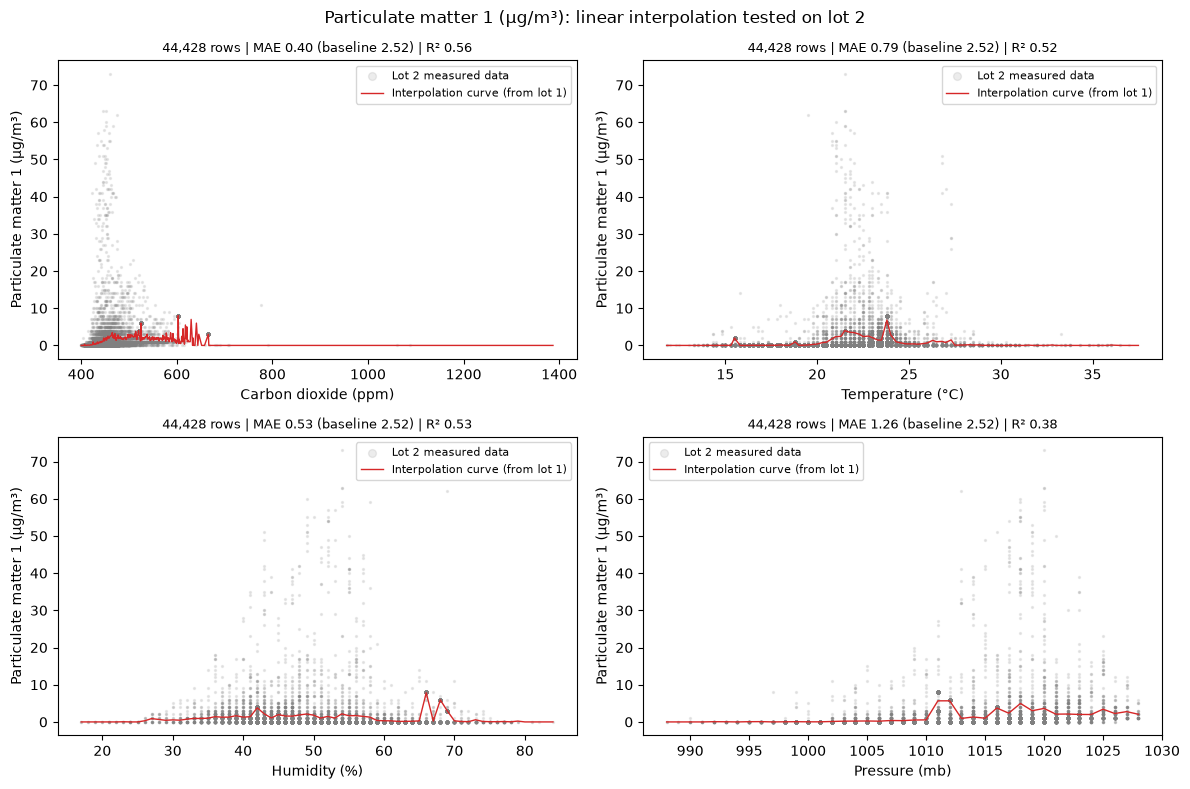

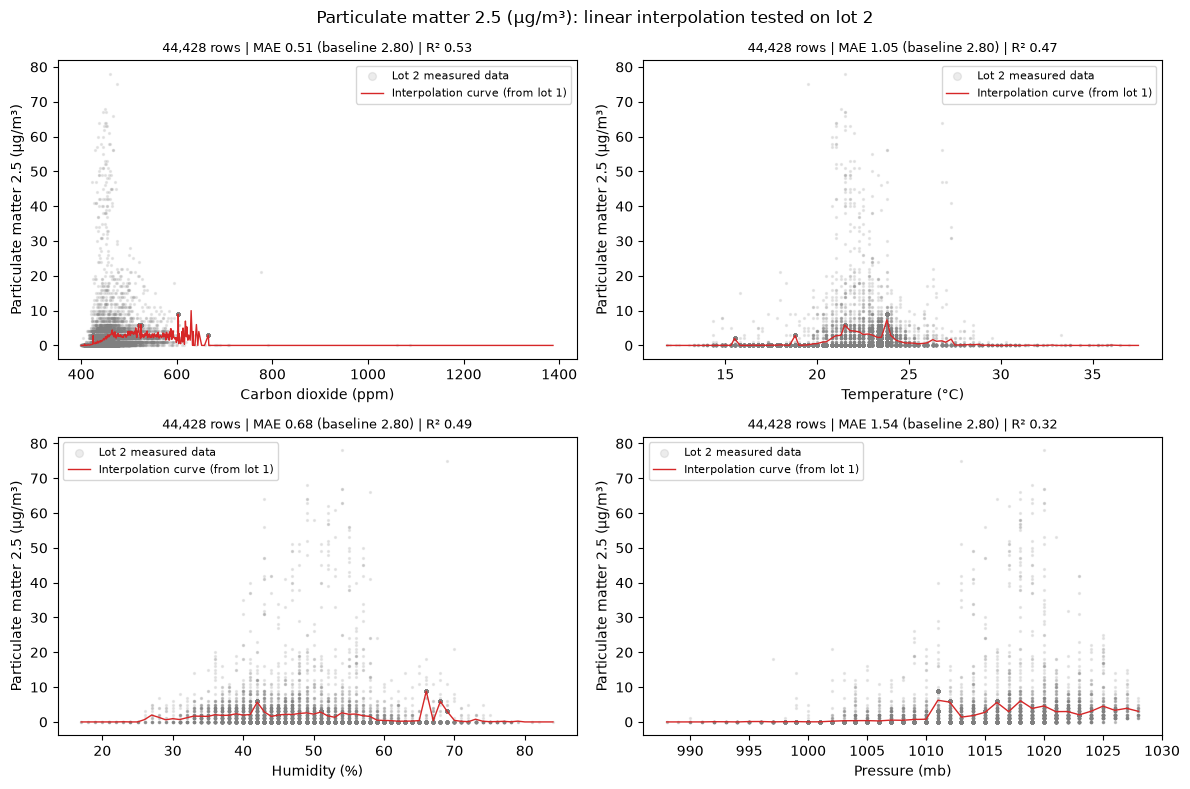

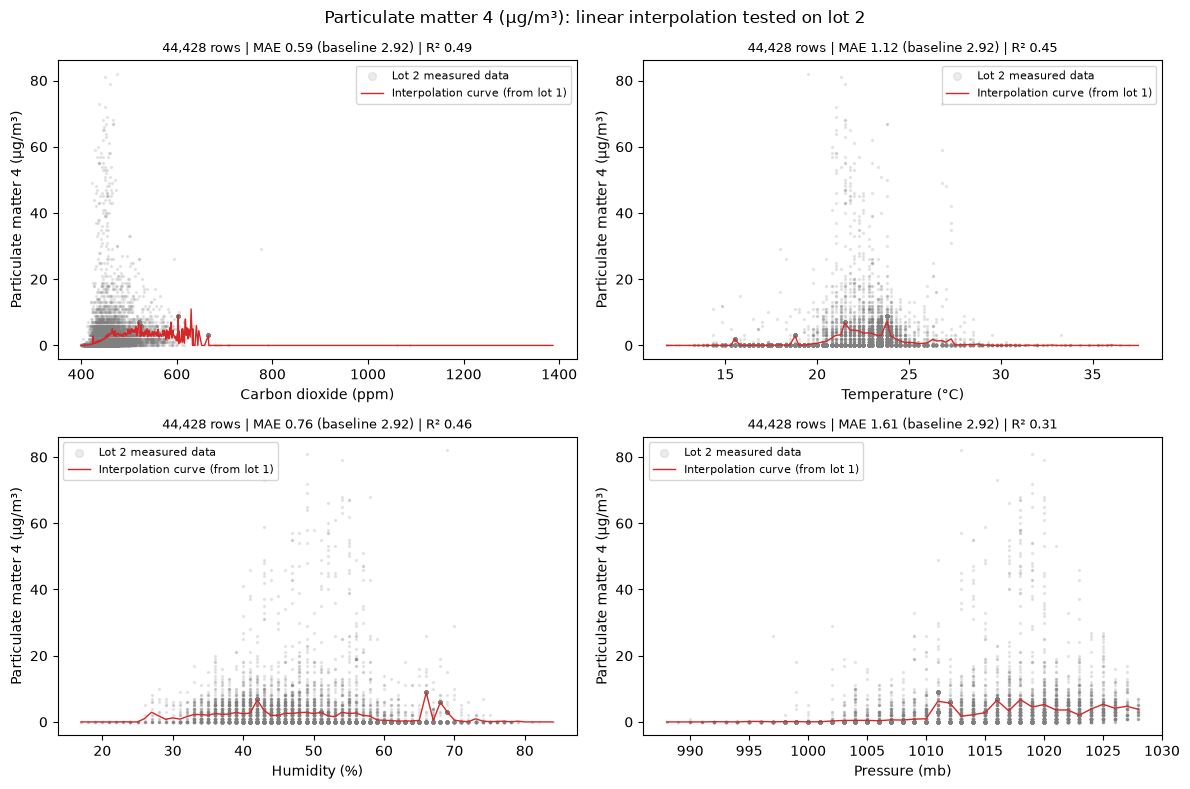

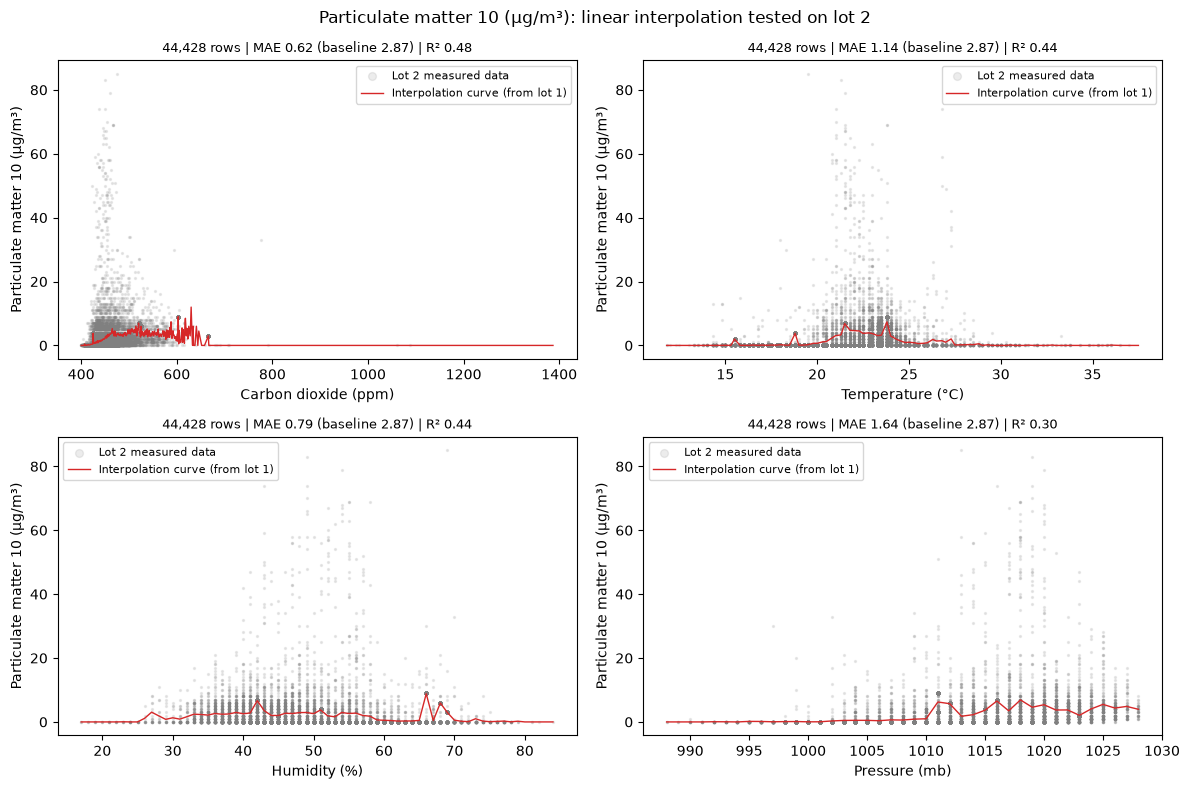

In [41]:
# Test linear interpolation using lot 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# ---- Predict every target from every predictor for each row of lot 2 ----
# Uses only the interpolation curves built from data lot 1
interp_lot_2 = interp_rows(data_lot_2)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
print("Predicted values using data set 2")
print(interp_lot_2.head().round(2).to_string(index=False))

# ---- Score the predictions against the measured values in lot 2 ----
# Only rows where the target was actually measured can be scored
eval_rows = []
for y_col in y_cols:
    for x_col in X_cols:
        known = data_lot_2[y_col].notna()
        y_true = data_lot_2.loc[known, y_col].to_numpy(float)
        y_pred = interp_lot_2.loc[known, f"{y_col} | from {x_col}"].to_numpy(float)

        eval_rows.append({
            "target": y_col,
            "predictor": x_col,
            "rows_scored": int(known.sum()),
            "R2": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            # Baseline: always predict the lot 1 mean of this target
            "mean_baseline_MAE": mean_absolute_error(
                y_true, np.full(len(y_true), data_lot_1[y_col].mean())),
        })

interp_eval = pd.DataFrame(eval_rows)
print()
print("SOMETHING!!!")
print(interp_eval.round(3).to_string(index=False))

# ---- Best predictor for each target (lowest MAE) ----
best = interp_eval.loc[interp_eval.groupby("target")["MAE"].idxmin(),
                       ["target", "predictor", "R2", "MAE", "RMSE", "mean_baseline_MAE"]]
print()
print("Best predictor table")
print(best.round(3).to_string(index=False))

# ---- Graphs: one figure per target, four panels (one per predictor) ----
# Grey dots = measured lot 2 values; red line = interpolation curve built from lot 1
score_lookup = interp_eval.set_index(["target", "predictor"])

for y_col in y_cols:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, x_col in zip(axes.ravel(), X_cols):
        xs, ys, _ = interp_tables[(y_col, x_col)]            # curve from lot 1
        pair = data_lot_2[[x_col, y_col]].dropna()           # measured lot 2 data
        row = score_lookup.loc[(y_col, x_col)]

        ax.scatter(pair[x_col], pair[y_col], s=2, alpha=0.15, color="grey",
                   label="Lot 2 measured data")
        ax.plot(xs, ys, color="tab:red", lw=1, label="Interpolation curve (from lot 1)")
        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)
        ax.set_title(f"{int(row['rows_scored']):,} rows | MAE {row['MAE']:.2f} "
                     f"(baseline {row['mean_baseline_MAE']:.2f}) | R² {row['R2']:.2f}",
                     fontsize=9)
        ax.legend(markerscale=4, fontsize=8)
    fig.suptitle(f"{y_col}: linear interpolation tested on lot 2")
    fig.tight_layout()
    plt.show()

Predicted values using data lot 1
     id  Carbon dioxide (ppm)  Temperature (°C)  Humidity (%)  Pressure (mb)  Formaldehyde (mg/m³) | from Carbon dioxide (ppm)  Formaldehyde (mg/m³) | from Temperature (°C)  Formaldehyde (mg/m³) | from Humidity (%)  Formaldehyde (mg/m³) | from Pressure (mb)  Light Volatile Organic Compounds (ppb) | from Carbon dioxide (ppm)  Light Volatile Organic Compounds (ppb) | from Temperature (°C)  Light Volatile Organic Compounds (ppb) | from Humidity (%)  Light Volatile Organic Compounds (ppb) | from Pressure (mb)  Particulate matter 1 (µg/m³) | from Carbon dioxide (ppm)  Particulate matter 1 (µg/m³) | from Temperature (°C)  Particulate matter 1 (µg/m³) | from Humidity (%)  Particulate matter 1 (µg/m³) | from Pressure (mb)  Particulate matter 2.5 (µg/m³) | from Carbon dioxide (ppm)  Particulate matter 2.5 (µg/m³) | from Temperature (°C)  Particulate matter 2.5 (µg/m³) | from Humidity (%)  Particulate matter 2.5 (µg/m³) | from Pressure (mb)  Particulate matter 4

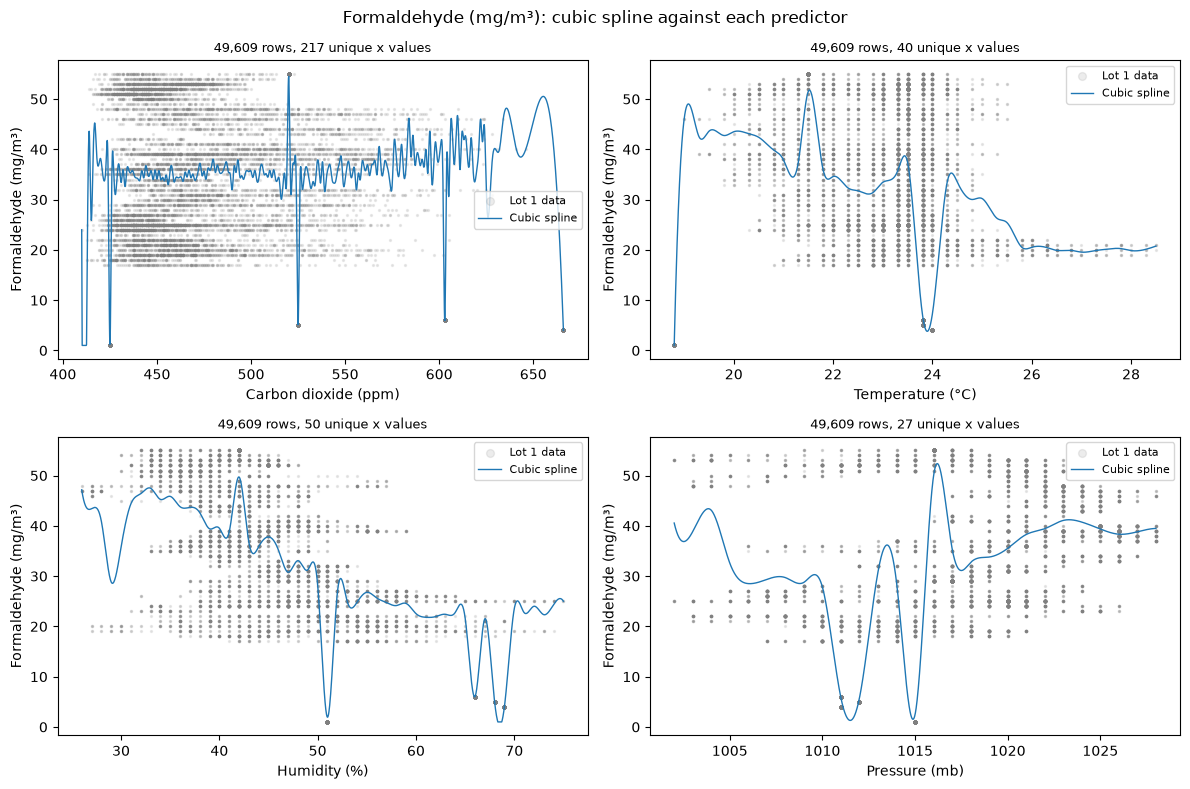

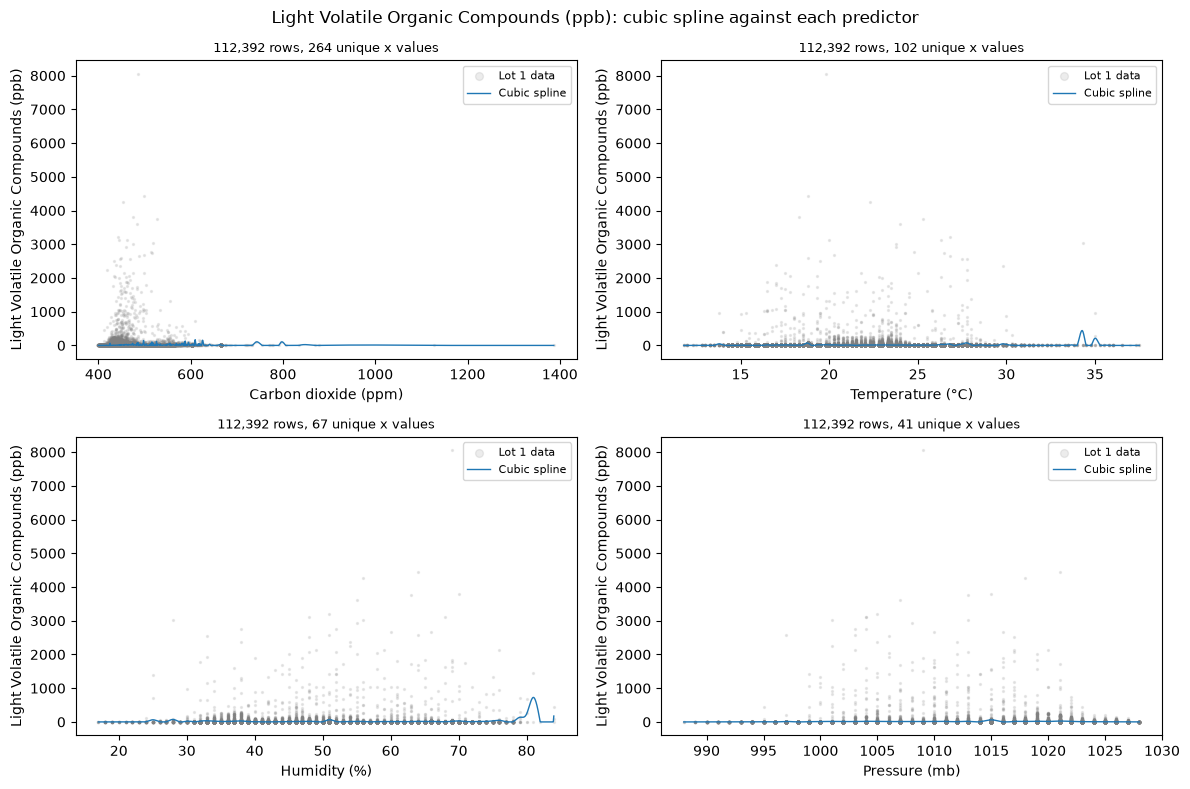

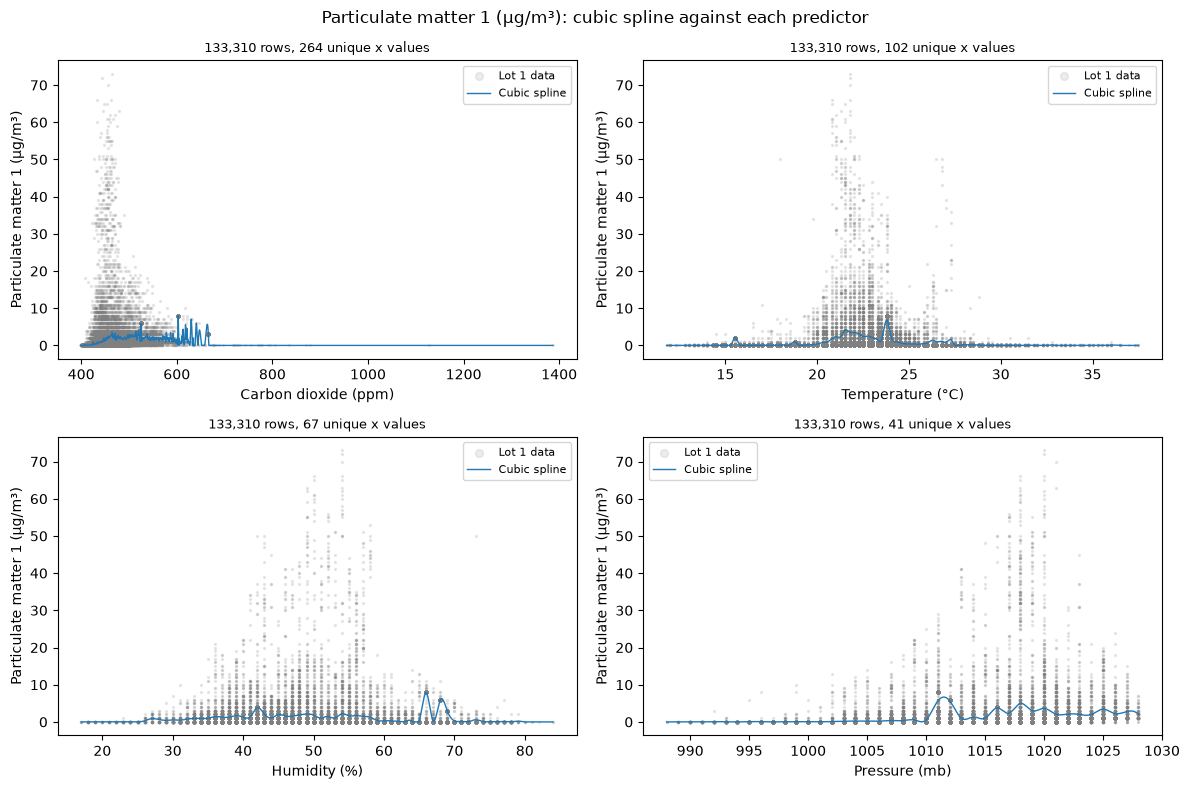

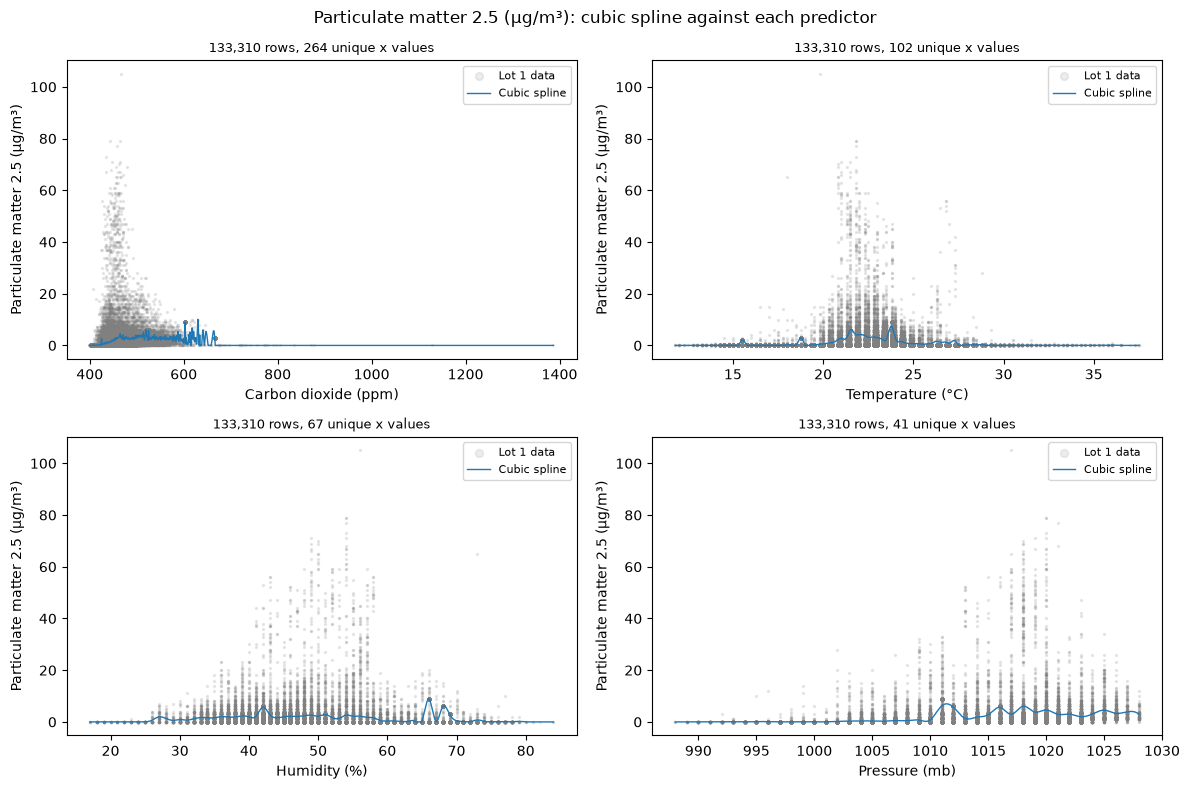

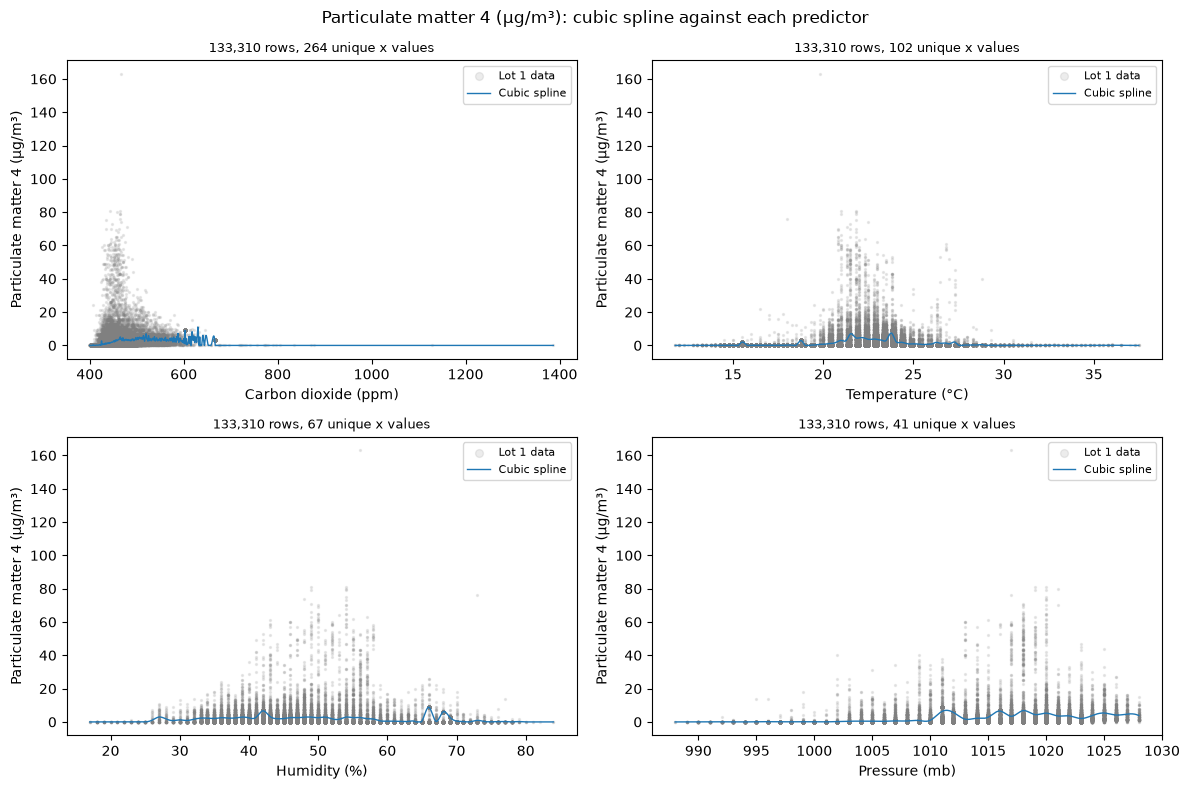

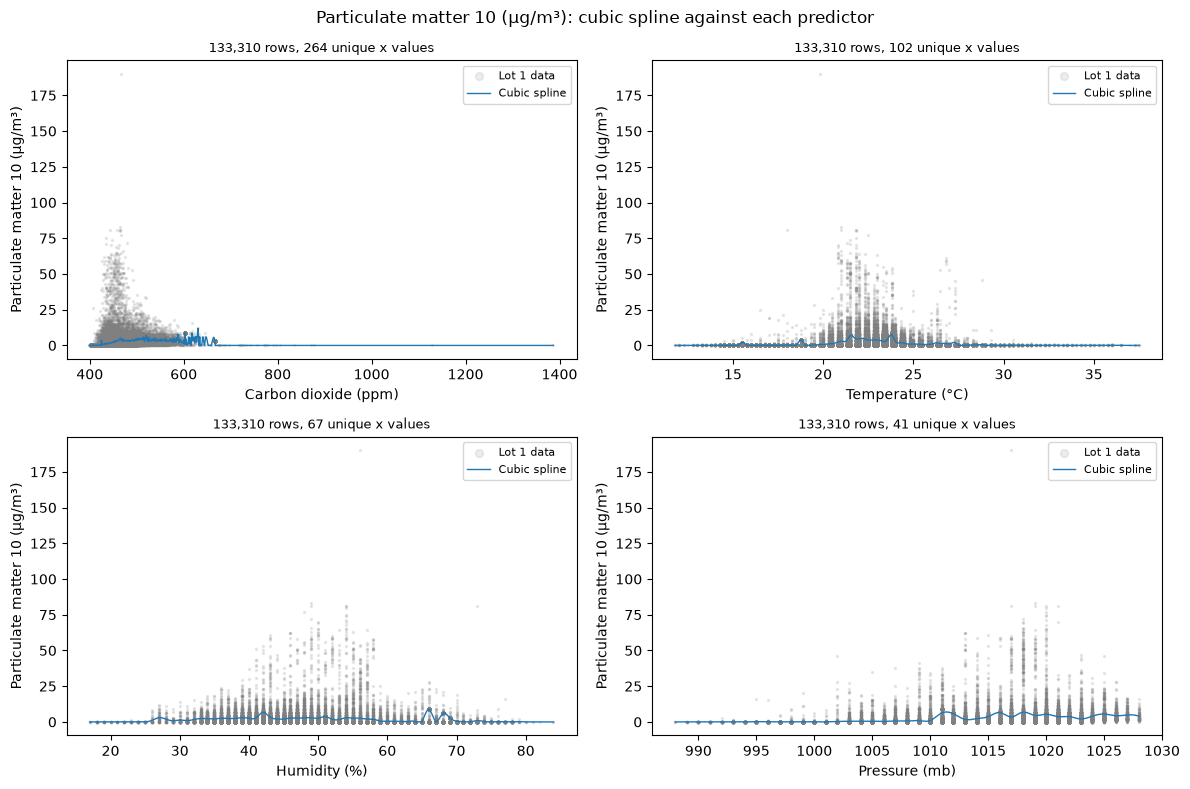

In [40]:
# Cubic spline interpolation code using lot 1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# ---- Build one cubic spline per (target, predictor) pair ----
# A spline needs strictly increasing, unique x values. Many rows share the same
# predictor value, so the target is averaged at each unique x (as in the linear case).
spline_tables = {}   # (target, predictor) -> (spline, x_min, x_max, lower, upper, rows used, unique x)

for y_col in y_cols:
    for x_col in X_cols:
        pair = data_lot_1[[x_col, y_col]].dropna()          # rows where both are known
        table = pair.groupby(x_col)[y_col].mean().sort_index()
        xs, ys = table.index.to_numpy(float), table.to_numpy(float)

        if len(xs) < 3:
            print(f"Skipped {y_col} vs {x_col}: only {len(xs)} unique x values")
            continue

        spline = CubicSpline(xs, ys)                         # default 'not-a-knot' end conditions

        # Physical limits: concentrations cannot be negative or exceed the observed maximum
        lower = max(0.0, pair[y_col].min())
        upper = pair[y_col].max()

        spline_tables[(y_col, x_col)] = (spline, xs.min(), xs.max(), lower, upper, len(pair), len(xs))

def spline_estimate(x_new, y_col, x_col):
    """Estimate target y_col from predictor x_col using its cubic spline.

    Inputs outside the lot 1 range are held at the nearest end (no extrapolation),
    and the output is clipped to the physical limits [lower, upper].
    """
    spline, x_min, x_max, lower, upper, _, _ = spline_tables[(y_col, x_col)]
    x_new = np.clip(np.asarray(x_new, dtype=float), x_min, x_max)
    return np.clip(spline(x_new), lower, upper)

# ---- Estimates for every row of a dataframe (24 columns) ----
def spline_rows(df):
    """Return id (if present), the predictors, and one cubic spline estimate
    per (target, predictor) pair for every row of df."""
    out = df[(["id"] if "id" in df.columns else []) + X_cols].copy()
    for y_col in y_cols:
        for x_col in X_cols:
            if (y_col, x_col) in spline_tables:
                out[f"{y_col} | from {x_col}"] = spline_estimate(df[x_col].to_numpy(float), y_col, x_col)
    return out

# ---- Table of estimates (printed first) ----
spline_lot_1 = spline_rows(data_lot_1)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
print("Predicted values using data lot 1")
print(spline_lot_1.head().round(2).to_string(index=False))

# ---- Plots: one figure per target, four panels (one per predictor) ----
for y_col in y_cols:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, x_col in zip(axes.ravel(), X_cols):
        if (y_col, x_col) not in spline_tables:
            ax.set_visible(False)
            continue
        _, x_min, x_max, _, _, n, n_unique = spline_tables[(y_col, x_col)]
        pair = data_lot_1[[x_col, y_col]].dropna()
        grid = np.linspace(x_min, x_max, 2000)

        ax.scatter(pair[x_col], pair[y_col], s=2, alpha=0.15, color="grey", label="Lot 1 data")
        ax.plot(grid, spline_estimate(grid, y_col, x_col), color="tab:blue", lw=1,
                label="Cubic spline")
        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)
        ax.set_title(f"{n:,} rows, {n_unique:,} unique x values", fontsize=9)
        ax.legend(markerscale=4, fontsize=8)
    fig.suptitle(f"{y_col}: cubic spline against each predictor")
    fig.tight_layout()
    plt.show()

Predicted values using data lot 2
     id  Carbon dioxide (ppm)  Temperature (°C)  Humidity (%)  Pressure (mb)  Formaldehyde (mg/m³) | from Carbon dioxide (ppm)  Formaldehyde (mg/m³) | from Temperature (°C)  Formaldehyde (mg/m³) | from Humidity (%)  Formaldehyde (mg/m³) | from Pressure (mb)  Light Volatile Organic Compounds (ppb) | from Carbon dioxide (ppm)  Light Volatile Organic Compounds (ppb) | from Temperature (°C)  Light Volatile Organic Compounds (ppb) | from Humidity (%)  Light Volatile Organic Compounds (ppb) | from Pressure (mb)  Particulate matter 1 (µg/m³) | from Carbon dioxide (ppm)  Particulate matter 1 (µg/m³) | from Temperature (°C)  Particulate matter 1 (µg/m³) | from Humidity (%)  Particulate matter 1 (µg/m³) | from Pressure (mb)  Particulate matter 2.5 (µg/m³) | from Carbon dioxide (ppm)  Particulate matter 2.5 (µg/m³) | from Temperature (°C)  Particulate matter 2.5 (µg/m³) | from Humidity (%)  Particulate matter 2.5 (µg/m³) | from Pressure (mb)  Particulate matter 4

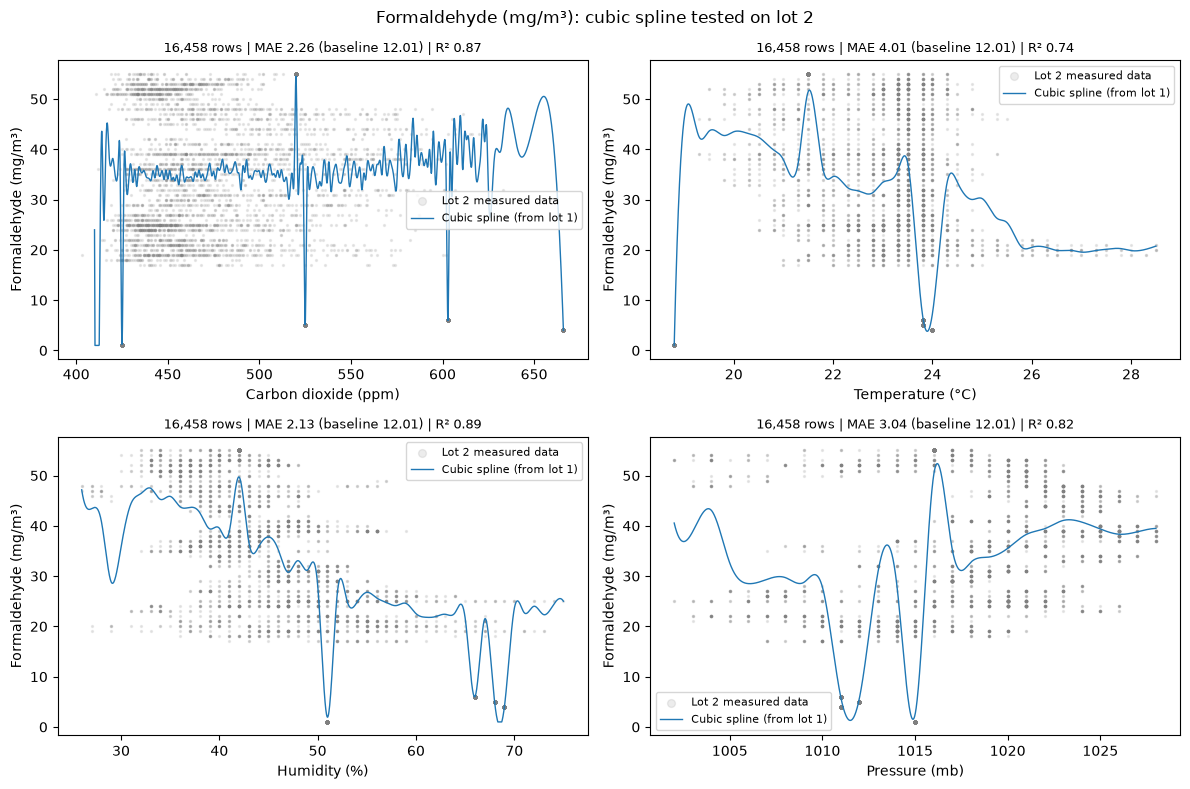

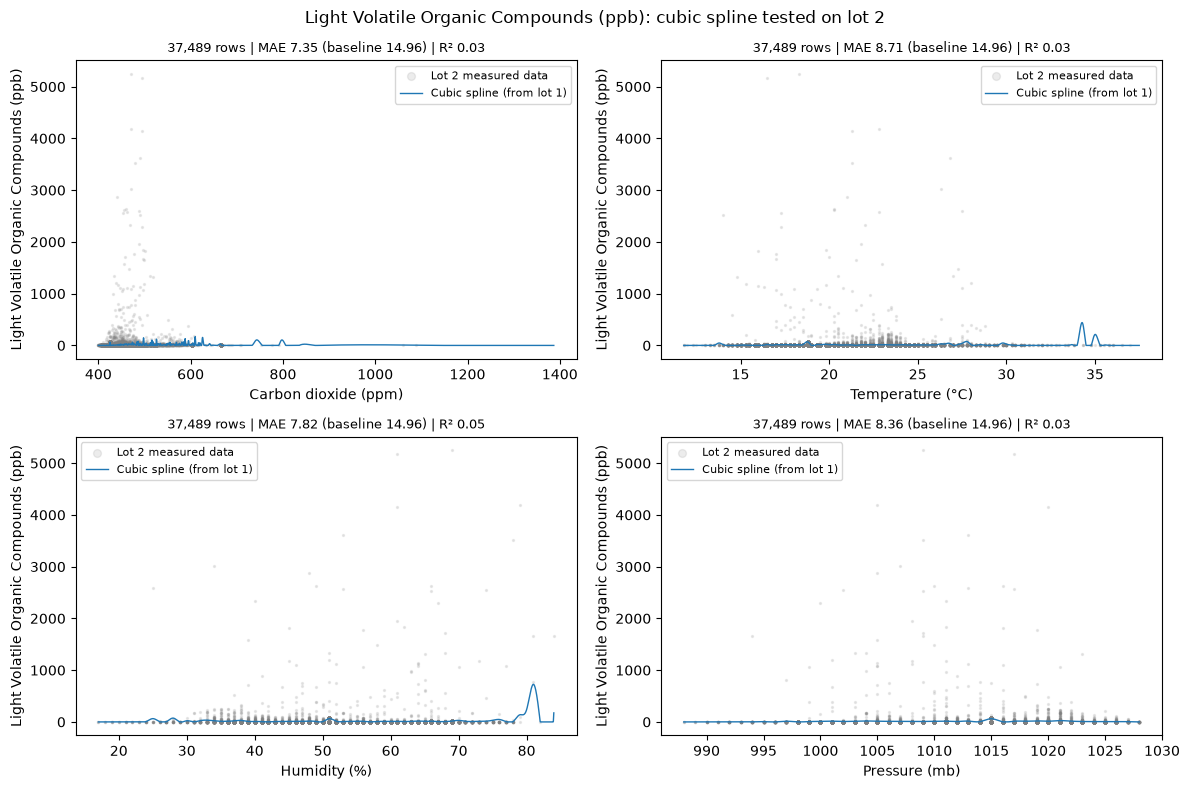

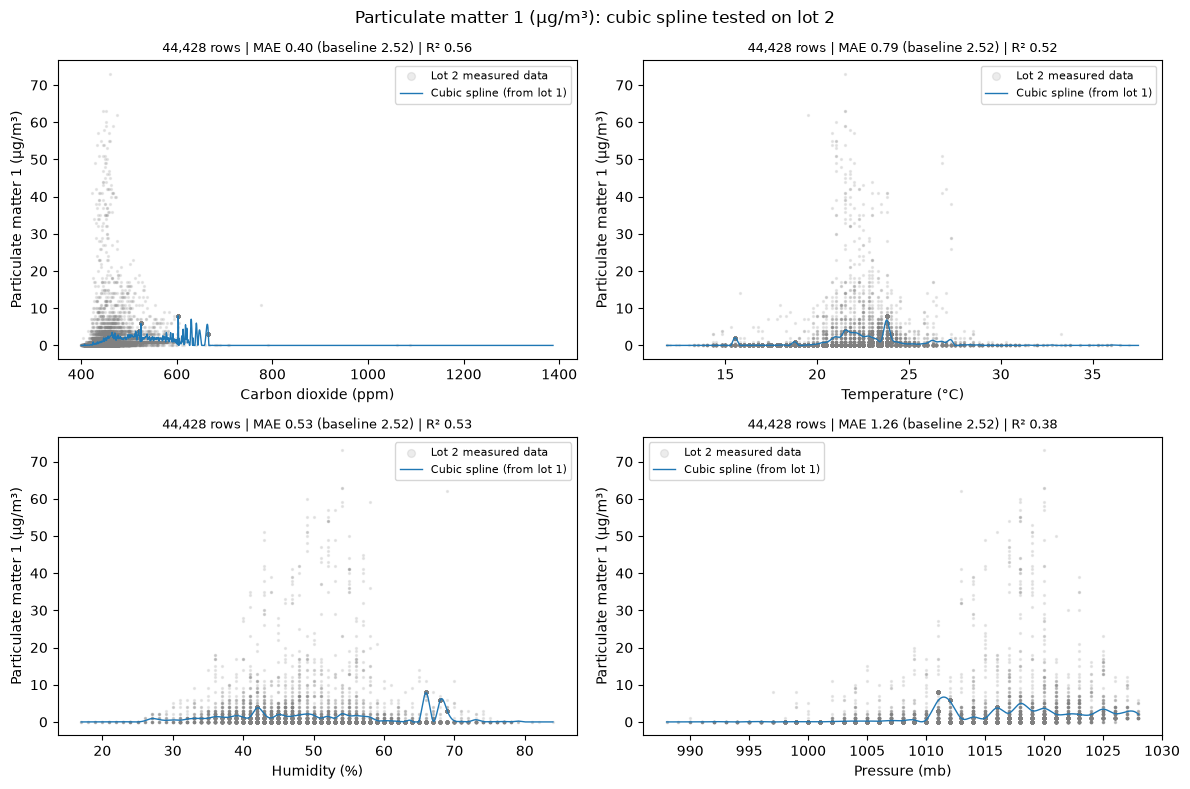

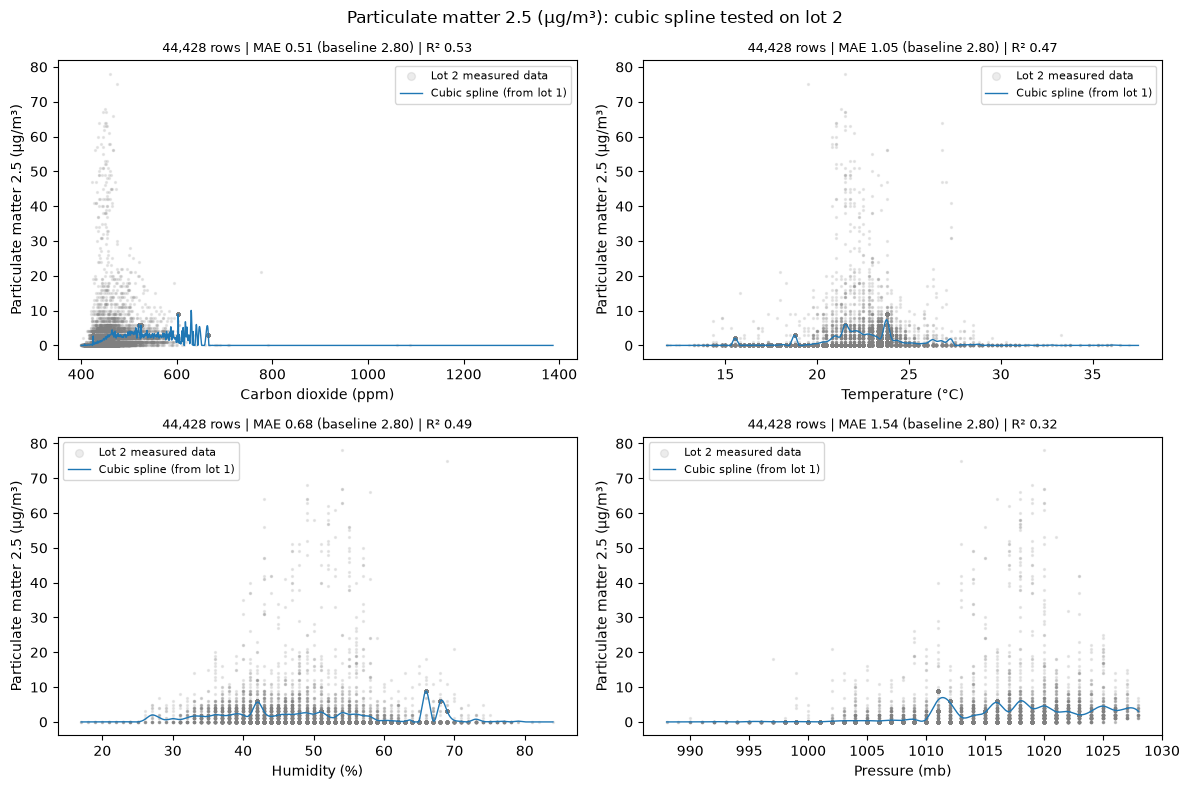

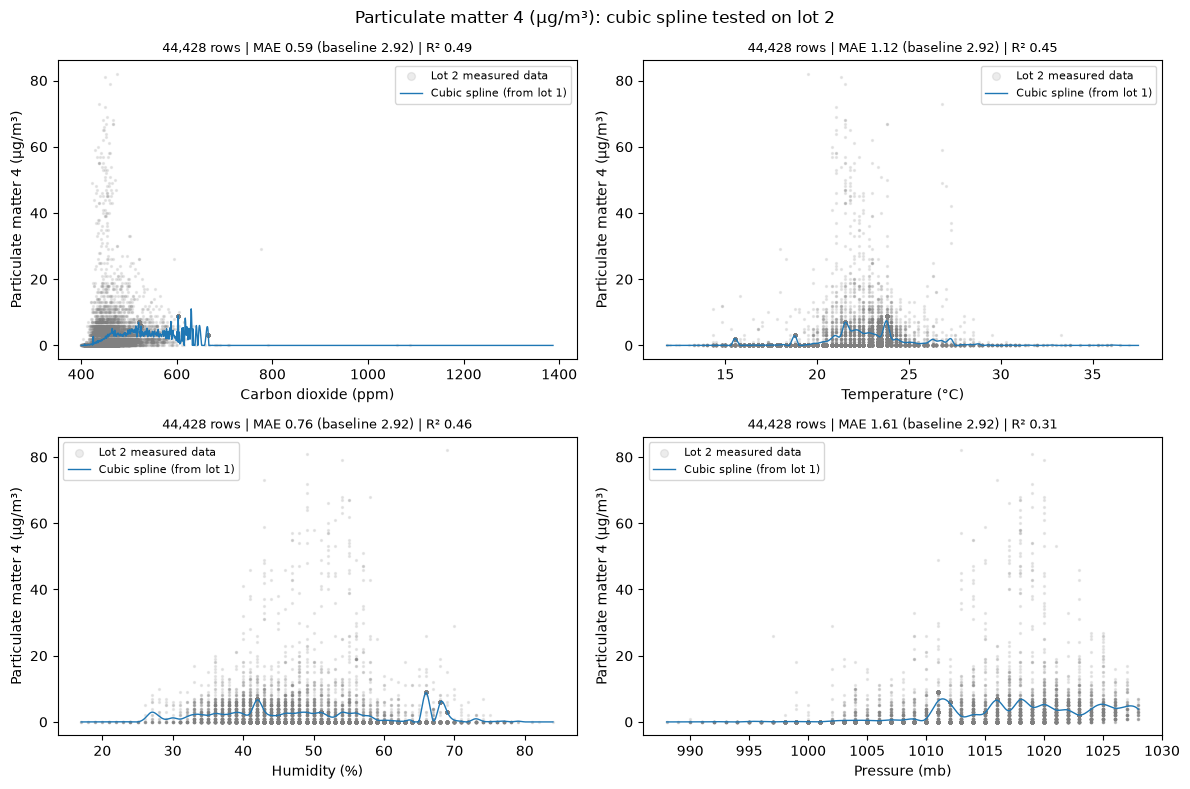

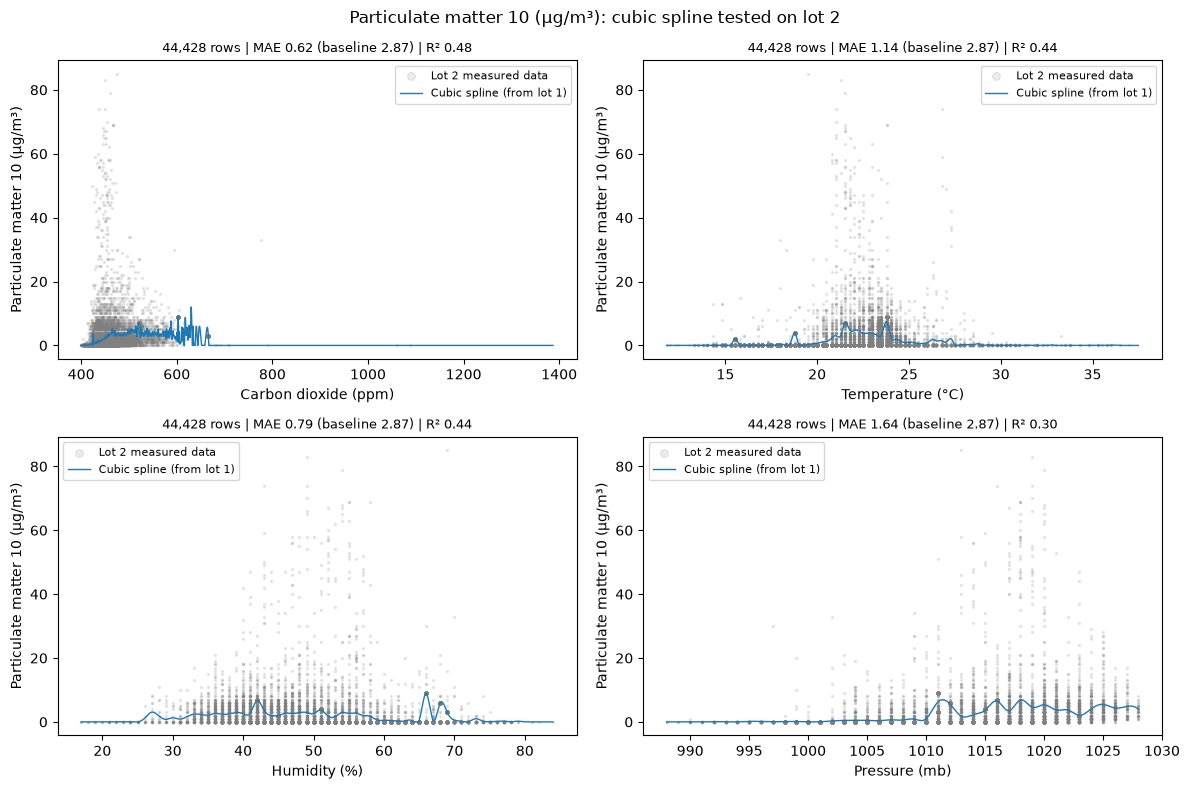

In [39]:
# Test cubic spline interpolation using lot 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# ---- Predict every target from every predictor for each row of lot 2 ----
# Uses only the cubic splines built from data lot 1
spline_lot_2 = spline_rows(data_lot_2)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
print("Predicted values using data lot 2")
print(spline_lot_2.head().round(2).to_string(index=False))

# ---- Score the predictions against the measured values in lot 2 ----
# Only rows where the target was actually measured can be scored
eval_rows = []
for y_col in y_cols:
    for x_col in X_cols:
        if (y_col, x_col) not in spline_tables:
            continue
        known = data_lot_2[y_col].notna()
        y_true = data_lot_2.loc[known, y_col].to_numpy(float)
        y_pred = spline_lot_2.loc[known, f"{y_col} | from {x_col}"].to_numpy(float)

        # Baseline: always predict the lot 1 mean of this target (same as the other methods)
        mean_baseline_mae = mean_absolute_error(
            y_true, np.full(len(y_true), data_lot_1[y_col].mean()))
        mae = mean_absolute_error(y_true, y_pred)

        eval_rows.append({
            "target": y_col,
            "predictor": x_col,
            "rows_scored": int(known.sum()),
            "R2": r2_score(y_true, y_pred),
            "MAE": mae,
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "mean_baseline_MAE": mean_baseline_mae,
            "skill_vs_baseline": 1 - mae / mean_baseline_mae,
            "MAE_pct_of_mean": 100 * mae / y_true.mean(),
        })

spline_eval = pd.DataFrame(eval_rows)
print()
print("SOMETHING!!!")
print(spline_eval.round(3).to_string(index=False))

# ---- Best predictor for each target (lowest MAE) ----
best_spline = spline_eval.loc[spline_eval.groupby("target")["MAE"].idxmin(),
                              ["target", "predictor", "R2", "MAE", "RMSE",
                               "mean_baseline_MAE", "skill_vs_baseline"]]
print()
print("Best predictor table")
print(best_spline.round(3).to_string(index=False))

# ---- Graphs: one figure per target, four panels (one per predictor) ----
# Grey dots = measured lot 2 values; blue line = cubic spline built from lot 1
score_lookup = spline_eval.set_index(["target", "predictor"])

for y_col in y_cols:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, x_col in zip(axes.ravel(), X_cols):
        if (y_col, x_col) not in spline_tables:
            ax.set_visible(False)
            continue
        _, x_min, x_max, _, _, _, _ = spline_tables[(y_col, x_col)]
        pair = data_lot_2[[x_col, y_col]].dropna()           # measured lot 2 data
        row = score_lookup.loc[(y_col, x_col)]
        grid = np.linspace(x_min, x_max, 2000)

        ax.scatter(pair[x_col], pair[y_col], s=2, alpha=0.15, color="grey",
                   label="Lot 2 measured data")
        ax.plot(grid, spline_estimate(grid, y_col, x_col), color="tab:blue", lw=1,
                label="Cubic spline (from lot 1)")
        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)
        ax.set_title(f"{int(row['rows_scored']):,} rows | MAE {row['MAE']:.2f} "
                     f"(baseline {row['mean_baseline_MAE']:.2f}) | R² {row['R2']:.2f}",
                     fontsize=9)
        ax.legend(markerscale=4, fontsize=8)
    fig.suptitle(f"{y_col}: cubic spline tested on lot 2")
    fig.tight_layout()
    plt.show()